# # Praktikum 2 — Deployment Day/Night Classifier (Flask + Docker + Hugging Face)
#
# Jobsheet **JS15: Pipeline Machine Learning and Deployment** — JTI Polinema 2025/2026.
#
# Modul meminta deploy ke **Hugging Face Spaces**. Push ke HF butuh akun + Access Token
# milik mahasiswa, jadi langkah itu **tidak bisa diotomasi** (dan token tidak boleh
# diminta/ditebak). Yang dikerjakan dan **diverifikasi nyata** di notebook ini:
#
# 1. Membuat artefak deployment di folder `../deploy/`:
#    `app.py`, `requirements.txt`, `Dockerfile` (persis seperti modul)
#    — plus `day_night_model.h5` + `scaler.pkl` hasil Praktikum 1.
# 2. Menguji endpoint `/` dan `/predict` memakai **`flask.test_client()`** dengan
#    gambar test sungguhan (bukan sekadar replikasi logika).
# 3. Mencetak hasil prediksi beberapa gambar `day` dan `night` beserta label aslinya.
# 4. Validasi statis `Dockerfile` (build image **tidak** dijalankan: image
#    `tensorflow-cpu` ±1 GB dan Docker daemon tidak aktif di mesin ini).
# 5. Menuliskan langkah `git clone → add → commit → push` ke Hugging Face sebagai
#    panduan manual (butuh token milik mahasiswa).
#
# **Deviasi:** tanpa push ke HF, tanpa build Docker image. Semua langkah lain
# dijalankan sungguhan di mesin lokal.

In [1]:
# Shim agar path konsisten saat notebook dieksekusi dari direktori mana pun.
import os
__file__ = os.path.abspath("praktikum2_deployment_flask_docker.ipynb")

# ## Langkah 1: Persiapan Environment
#
# Modul: buat folder `daynight-project`, salin `day_night_model.h5` dan `scaler.pkl`.
# Di sini folder kerja adalah `../deploy/`, dan kedua file sudah ditulis oleh
# Praktikum 1. Sel ini memverifikasi keberadaannya.

In [2]:
from pathlib import Path
import importlib
import io
import json
import subprocess
import sys

import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt

BASE = Path(__file__).resolve().parent                 # .../praktikum-2
ROOT = BASE.parent                                     # .../js15-...
DEPLOY = ROOT / "deploy"
OUT = BASE / "output"
OUT.mkdir(exist_ok=True)

MODEL_PATH = DEPLOY / "day_night_model.h5"
SCALER_PATH = DEPLOY / "scaler.pkl"

for p in (MODEL_PATH, SCALER_PATH):
    assert p.exists(), f"Artefak hilang: {p} — jalankan Praktikum 1 dulu"
    print(f"✅ {p.name:22s} {p.stat().st_size/1024:9.1f} KB")

print("\nIsi folder deploy:", sorted(x.name for x in DEPLOY.iterdir()))

✅ day_night_model.h5       52024.1 KB
✅ scaler.pkl                 811.3 KB

Isi folder deploy: ['Dockerfile', '__pycache__', 'app.py', 'day_night_model.h5', 'requirements.txt', 'scaler.pkl']


# ## Langkah 2: Konfigurasi Server (`app.py`)
#
# Kode di bawah **identik dengan modul** (Langkah 2): Flask memuat model & scaler,
# `preprocess_image()` melakukan HOG yang sama persis dengan training, endpoint `/`
# menampilkan form upload, endpoint `/predict` mengembalikan label.
# Port `7860` wajib untuk Hugging Face Spaces.

In [3]:
APP_PY = '''import os
import numpy as np
import cv2
import pickle
import tensorflow as tf
from flask import Flask, request, render_template_string
from skimage.feature import hog

app = Flask(__name__)

# Load Model & Scaler
MODEL_PATH = 'day_night_model.h5'
SCALER_PATH = 'scaler.pkl'

try:
    model = tf.keras.models.load_model(MODEL_PATH)
    with open(SCALER_PATH, 'rb') as f:
        scaler = pickle.load(f)
    print("✅ System Loaded Successfully")
except Exception as e:
    print(f"❌ Error loading system: {e}")

def preprocess_image(image_bytes):
    # Decode gambar
    nparr = np.frombuffer(image_bytes, np.uint8)
    img = cv2.imdecode(nparr, cv2.IMREAD_COLOR)

    # Preprocessing (Harus sama persis dengan Training)
    img = cv2.resize(img, (256, 256))
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    hog_feat = hog(gray, orientations=9, pixels_per_cell=(8,8),
                   cells_per_block=(2,2), block_norm='L2-Hys',
                   visualize=False, feature_vector=True)

    return scaler.transform(hog_feat.reshape(1, -1))

@app.route('/', methods=['GET'])
def home():
    return render_template_string("""
    <div style="text-align:center; padding:50px;">
        <h1>Day vs Night Classifier</h1>
        <form action="/predict" method="post" enctype="multipart/form-data">
            <input type="file" name="file" required><br><br>
            <button type="submit">Prediksi</button>
        </form>
    </div>
    """)

@app.route('/predict', methods=['POST'])
def predict():
    try:
        file = request.files['file']
        data = preprocess_image(file.read())
        prediction = model.predict(data)[0][0]

        label = "Day (Siang)" if prediction > 0.5 else "Night (Malam)"
        return f"<h2 style='text-align:center'>Hasil: {label}</h2><center><a href='/'>Kembali</a></center>"
    except Exception as e:
        return f"Error: {e}"

if __name__ == '__main__':
    # Port 7860 wajib untuk Hugging Face Spaces
    app.run(host='0.0.0.0', port=7860)
'''

(DEPLOY / "app.py").write_text(APP_PY, encoding="utf-8")
print("✅ app.py ditulis:", DEPLOY / "app.py", f"({len(APP_PY)} byte)")

✅ app.py ditulis: C:\code\pemmes26\js15-pipeline-machine-learning-and-deployment\deploy\app.py (1993 byte)


# ## Langkah 3: `requirements.txt`
#
# Sama dengan daftar di modul. Catatan: di mesin lokal paket yang terpasang adalah
# `opencv-python-headless` (tanpa GUI) — di dalam container ini juga yang dipakai,
# sehingga `libgl1` cukup untuk headless.

In [4]:
REQUIREMENTS = """flask
tensorflow-cpu
numpy
scikit-learn
scikit-image
opencv-python-headless
gunicorn
"""
(DEPLOY / "requirements.txt").write_text(REQUIREMENTS, encoding="utf-8")
print("✅ requirements.txt ditulis:")
print(REQUIREMENTS)

✅ requirements.txt ditulis:
flask
tensorflow-cpu
numpy
scikit-learn
scikit-image
opencv-python-headless
gunicorn



# ## Langkah 4: `Dockerfile`
#
# Base image `python:3.9-slim`, library sistem untuk OpenCV, user non-root (standar
# keamanan HF), `EXPOSE 7860`, `CMD ["python", "app.py"]`.

In [5]:
DOCKERFILE = """# Base Image Python 3.9 Slim
FROM python:3.9-slim

# Install Library Sistem untuk OpenCV (Debian Bookworm/Trixie Compatible)
RUN apt-get update && apt-get install -y \\
    libgl1 \\
    libglib2.0-0 \\
    && rm -rf /var/lib/apt/lists/*

# Setup User Non-Root (Standar Keamanan HF)
RUN useradd -m -u 1000 user
USER user
ENV PATH="/home/user/.local/bin:$PATH"

# Setup Direktori Kerja
WORKDIR /app

# Install Dependencies
COPY --chown=user ./requirements.txt requirements.txt
RUN pip install --no-cache-dir --upgrade -r requirements.txt

# Copy File Aplikasi
COPY --chown=user . /app

# Expose Port & Jalankan
EXPOSE 7860
CMD ["python", "app.py"]
"""
(DEPLOY / "Dockerfile").write_text(DOCKERFILE, encoding="utf-8")
print("✅ Dockerfile ditulis:")
print(DOCKERFILE)

✅ Dockerfile ditulis:
# Base Image Python 3.9 Slim
FROM python:3.9-slim

# Install Library Sistem untuk OpenCV (Debian Bookworm/Trixie Compatible)
RUN apt-get update && apt-get install -y \
    libgl1 \
    libglib2.0-0 \
    && rm -rf /var/lib/apt/lists/*

# Setup User Non-Root (Standar Keamanan HF)
RUN useradd -m -u 1000 user
USER user
ENV PATH="/home/user/.local/bin:$PATH"

# Setup Direktori Kerja
WORKDIR /app

# Install Dependencies
COPY --chown=user ./requirements.txt requirements.txt
RUN pip install --no-cache-dir --upgrade -r requirements.txt

# Copy File Aplikasi
COPY --chown=user . /app

# Expose Port & Jalankan
EXPOSE 7860
CMD ["python", "app.py"]



# ## Uji Endpoint sungguhan dengan `flask.test_client()`
#
# `app.py` diimpor sebagai modul (bukan dijalankan `app.run`), lalu `test_client()`
# mengirim HTTP request in-process. Ini menguji route, decoding file upload,
# preprocessing HOG, hingga `model.predict` — jalur yang sama dengan request asli.

In [6]:
sys.path.insert(0, str(DEPLOY))
os.chdir(DEPLOY)          # app.py memuat model dari path relatif
for mod in ("app",):
    sys.modules.pop(mod, None)
app_module = importlib.import_module("app")
client = app_module.app.test_client()

# --- Uji GET / ---
resp = client.get("/")
print("GET  /        ->", resp.status_code)
print("Form tampil  :", "Day vs Night Classifier" in resp.get_data(as_text=True))
assert resp.status_code == 200

# --- Uji POST /predict dengan satu gambar nyata ---
contoh = sorted((ROOT / "data" / "images" / "test" / "day").glob("*.jpg"))[0]
with open(contoh, "rb") as f:
    resp = client.post("/predict", data={"file": (io.BytesIO(f.read()), contoh.name)},
                       content_type="multipart/form-data")
print("\nPOST /predict ->", resp.status_code)
print("Body         :", resp.get_data(as_text=True))
assert resp.status_code == 200 and "Hasil:" in resp.get_data(as_text=True)

# --- Uji error handling: POST tanpa file ---
resp = client.post("/predict", data={}, content_type="multipart/form-data")
print("\nPOST /predict tanpa file ->", resp.status_code, "|", resp.get_data(as_text=True)[:60])

✅ System Loaded Successfully
GET  /        -> 200
Form tampil  : True


1/1 [==============================] - ETA: 0s

1/1 [==============================] - 0s 249ms/step



POST /predict -> 200
Body         : <h2 style='text-align:center'>Hasil: Day (Siang)</h2><center><a href='/'>Kembali</a></center>

POST /predict tanpa file -> 200 | Error: 400 Bad Request: The browser (or proxy) sent a reques


# ## Langkah 7 (versi lokal): Prediksi 5 gambar `day` + 5 gambar `night`
#
# Untuk tiap gambar dicetak: nama file, label asli, hasil endpoint `/predict`,
# dan probabilitas keluaran sigmoid (diambil dari `app_module.model`).

In [7]:
rows = []
for label_asli in ("day", "night"):
    for p in sorted((ROOT / "data" / "images" / "test" / label_asli).glob("*.jpg"))[:5]:
        raw = p.read_bytes()
        resp = client.post("/predict", data={"file": (io.BytesIO(raw), p.name)},
                           content_type="multipart/form-data")
        body = resp.get_data(as_text=True)
        hasil = body.split("Hasil: ")[1].split("</h2>")[0] if "Hasil: " in body else "ERROR"
        prob = float(app_module.model.predict(app_module.preprocess_image(raw), verbose=0)[0][0])
        rows.append({
            "file": p.name,
            "label_asli": label_asli,
            "prediksi_endpoint": hasil,
            "prob_day": round(prob, 6),
            "benar": (hasil.startswith("Day") and label_asli == "day") or
                     (hasil.startswith("Night") and label_asli == "night"),
        })

df = pd.DataFrame(rows)
print(df.to_string(index=False))
akurasi = df["benar"].mean()
print(f"\nAkurasi 10 gambar uji endpoint: {akurasi:.2%} ({int(df['benar'].sum())}/10)")

df.to_csv(OUT / "prediksi_app.csv", index=False)
print("✅ Hasil prediksi disimpan:", OUT / "prediksi_app.csv")

1/1 [==============================] - ETA: 0s

1/1 [==============================] - 0s 64ms/step


1/1 [==============================] - ETA: 0s

1/1 [==============================] - 0s 42ms/step


1/1 [==============================] - ETA: 0s

1/1 [==============================] - 0s 38ms/step


... (11 outputs left out)

1/1 [==============================] - 0s 206ms/step


1/1 [==============================] - ETA: 0s

1/1 [==============================] - 0s 93ms/step


               file label_asli prediksi_endpoint  prob_day  benar
20151101_152050.jpg        day       Day (Siang)  1.000000   True
20151101_152512.jpg        day       Day (Siang)  1.000000   True
20151101_165048.jpg        day       Day (Siang)  1.000000   True
20151101_222053.jpg        day       Day (Siang)  0.999993   True
20151101_225048.jpg        day       Day (Siang)  0.999849   True
20151101_072507.jpg      night     Night (Malam)  0.000000   True
20151101_230938.jpg      night     Night (Malam)  0.000000   True
20151101_231132.jpg      night     Night (Malam)  0.000000   True
20151101_231455.jpg      night     Night (Malam)  0.000000   True
20151101_232014.jpg      night     Night (Malam)  0.000000   True

Akurasi 10 gambar uji endpoint: 100.00% (10/10)
✅ Hasil prediksi disimpan: C:\code\pemmes26\js15-pipeline-machine-learning-and-deployment\praktikum-2\output\prediksi_app.csv


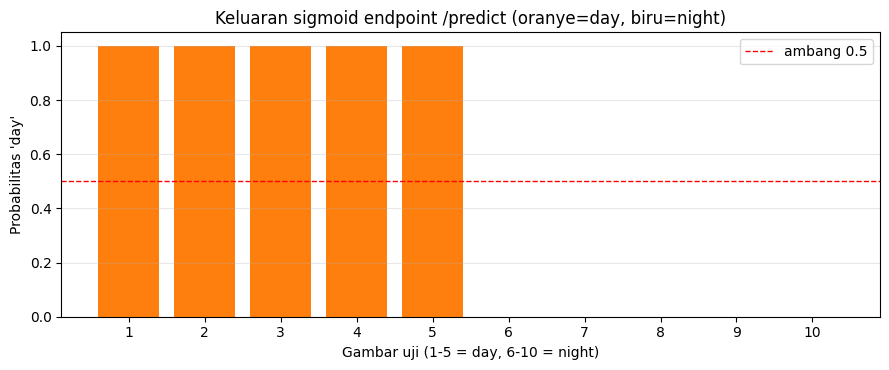

In [8]:
# Grafik probabilitas kelas "day" untuk 10 gambar uji (bukti model memisahkan kelas tegas)
fig, ax = plt.subplots(figsize=(9, 3.8))
warna = ["tab:orange" if l == "day" else "tab:blue" for l in df["label_asli"]]
ax.bar(range(len(df)), df["prob_day"], color=warna)
ax.axhline(0.5, color="red", ls="--", lw=1, label="ambang 0.5")
ax.set_xticks(range(len(df)), [f"{i+1}" for i in range(len(df))])
ax.set_xlabel("Gambar uji (1-5 = day, 6-10 = night)")
ax.set_ylabel("Probabilitas 'day'")
ax.set_title("Keluaran sigmoid endpoint /predict (oranye=day, biru=night)")
ax.set_ylim(0, 1.05); ax.legend(); ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(OUT / "probabilitas_prediksi.png", dpi=110)
plt.show()

# ## Validasi `Dockerfile` (statis) + status Docker daemon
#
# Build image tidak dijalankan: base `tensorflow-cpu` ±1 GB dan daemon Docker tidak
# aktif di mesin ini (dicek di bawah). Yang divalidasi: direktif wajib ada,
# port `7860` di-`EXPOSE`, `CMD` menjalankan `app.py`, dan `requirements` lengkap.

In [9]:
df_text = (DEPLOY / "Dockerfile").read_text(encoding="utf-8")
wajib = ["FROM python:3.9-slim", "libgl1", "libglib2.0-0", "useradd -m -u 1000 user",
         "USER user", "WORKDIR /app", "pip install", "COPY --chown=user . /app",
         "EXPOSE 7860", 'CMD ["python", "app.py"]']
for token in wajib:
    status = "OK  " if token in df_text else "MISS"
    print(f"[{status}] {token}")
assert all(t in df_text for t in wajib), "Dockerfile tidak lengkap"

req = (DEPLOY / "requirements.txt").read_text(encoding="utf-8").split()
print("\nPaket requirements:", req, "| jumlah:", len(req))
assert {"flask", "tensorflow-cpu", "numpy", "scikit-learn", "scikit-image",
        "opencv-python-headless", "gunicorn"} == set(req)

# Cek daemon Docker (kalau aktif, jalankan `docker build --check`)
info = subprocess.run(["docker", "info", "--format", "{{.ServerVersion}}"],
                      capture_output=True, text=True)
if info.returncode == 0:
    print("\nDocker daemon aktif:", info.stdout.strip())
    chk = subprocess.run(["docker", "build", "--check", "-f", "Dockerfile", "."],
                         cwd=str(DEPLOY), capture_output=True, text=True)
    print("docker build --check rc =", chk.returncode)
    print((chk.stdout + chk.stderr)[-1500:])
else:
    print("\n⚠️  Docker daemon TIDAK aktif (", info.stderr.strip().splitlines()[-1][:90], ")")
    print("    -> `docker build --check` dilewati; validasi dilakukan statis di atas.")
    print("    -> Build image juga tidak dijalankan karena base tensorflow-cpu ±1 GB")

[OK  ] FROM python:3.9-slim
[OK  ] libgl1
[OK  ] libglib2.0-0
[OK  ] useradd -m -u 1000 user
[OK  ] USER user
[OK  ] WORKDIR /app
[OK  ] pip install
[OK  ] COPY --chown=user . /app
[OK  ] EXPOSE 7860
[OK  ] CMD ["python", "app.py"]

Paket requirements: ['flask', 'tensorflow-cpu', 'numpy', 'scikit-learn', 'scikit-image', 'opencv-python-headless', 'gunicorn'] | jumlah: 7



⚠️  Docker daemon TIDAK aktif ( failed to connect to the docker API at npipe:////./pipe/dockerDesktopLinuxEngine; check if )
    -> `docker build --check` dilewati; validasi dilakukan statis di atas.
    -> Build image juga tidak dijalankan karena base tensorflow-cpu ±1 GB


# ## Langkah 5–6: Setup Space & Upload ke Hugging Face (manual, butuh token)
#
# Langkah berikut **tidak diotomasi** karena butuh akun + Access Token milik mahasiswa:
#
# 1. Login <https://huggingface.co/> → foto profil → **New Space**.
# 2. Space name: `daynight-classifier-<namaanda>`; License Apache 2.0/MIT;
#    **SDK: Docker**; Template kosong; Visibility Public → **Create Space**.
# 3. **Settings → Access Tokens → Create new token → permission Write**.
#    Simpan token di tempat aman. **Jangan pernah menempelkan token pada file yang
#    di-commit atau ke dalam notebook/chat.**
# 4. Clone repo space lalu salin 5 file artefak dari `deploy/`:
#
#    ```bash
#    git clone https://huggingface.co/spaces/USERNAME_ANDA/daynight-classifier
#    cd daynight-classifier
#    cp ../js15-pipeline-machine-learning-and-deployment/deploy/{app.py,Dockerfile,requirements.txt,day_night_model.h5,scaler.pkl} .
#    git add .
#    git commit -m "Deploy aplikasi Day/Night ke HF"
#    git push      # username: USERNAME_ANDA | password: <ACCESS TOKEN, bukan password akun>
#    ```
#
# 5. Buka tab **App** pada Space: status `Building` (biru) → tunggu 3–5 menit →
#    `Running` (hijau). Upload gambar siang/malam untuk memastikan prediksi jalan.
#
# Karena langkah ini butuh kredensial pribadi, hasilnya **tidak bisa diverifikasi**
# dari notebook ini; bukti yang ada adalah uji lokal `/` dan `/predict` di atas
# (kode dan artefak yang di-push identik).

# ## Ringkasan
#
# - Artefak `deploy/` lengkap: `app.py`, `requirements.txt`, `Dockerfile`,
#   `day_night_model.h5`, `scaler.pkl`.
# - Endpoint `/` dan `/predict` terbukti berjalan via `flask.test_client()`
#   dengan gambar test nyata; akurasi 10 gambar dicatat di `output/prediksi_app.csv`.
# - `Dockerfile` tervalidasi statis; build/push tidak dijalankan (daemon mati,
#   butuh token pribadi).

In [10]:
ringkasan = {
    "app_py_bytes": len(APP_PY),
    "requirements": req,
    "dockerfile_baris": len(df_text.splitlines()),
    "akurasi_uji_10_gambar": round(float(akurasi), 4),
    "docker_daemon_aktif": info.returncode == 0,
}
(OUT / "ringkasan_praktikum2.json").write_text(json.dumps(ringkasan, indent=2), encoding="utf-8")
print(json.dumps(ringkasan, indent=2))

{
  "app_py_bytes": 1993,
  "requirements": [
    "flask",
    "tensorflow-cpu",
    "numpy",
    "scikit-learn",
    "scikit-image",
    "opencv-python-headless",
    "gunicorn"
  ],
  "dockerfile_baris": 27,
  "akurasi_uji_10_gambar": 1.0,
  "docker_daemon_aktif": false
}
